# Pipeline walkthrough: every step, opened

This notebook opens each layer of the pipeline in the order the data flows through it and shows what is inside.
The DuckDB file (4.7 GB) and the raw files are not in the repository, so the saved outputs here are the record of
what they contain. Nothing is written: DuckDB is opened read-only and BigQuery is only queried.

| Step | Folder | Opened here |
|---|---|---|
| 1 Ingest | `1_ingestion/` | DuckDB: the two raw tables, their columns and sample rows |
| 2 Label | `2_enrichment/` | DuckDB: the flower labels, review themes, wish sentences and the 2026 snapshot |
| 3 Load | `3_meltano/` | BigQuery `project2_raw`: the same tables, row counts next to DuckDB |
| 4 Transform | `4_dbt/` | BigQuery staging, analytics (star schema) and marts |
| 5 Test | `4_dbt/tests/`, `5_quality/` | dbt test results and Great Expectations rules |
| 6 Reconcile | `6_reconcile/` | the warehouse results compared with the frozen contract |
| 7 Orchestrate | `7_orchestration/` | the last Dagster run, step by step |
| 8 Analyse | `8_notebooks/` | continues in `flower_analysis.ipynb` |

In [1]:
import json
import os
import re
import warnings
from pathlib import Path

import duckdb
import pandas as pd
from IPython.display import Image, Markdown, display
from sqlalchemy import create_engine, text

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.width', 200)

REPO = Path.cwd().parent if Path.cwd().name == '8_notebooks' else Path.cwd()
EVIDENCE = REPO / 'docs' / 'evidence'
duck = duckdb.connect(str(REPO / 'duckdb' / 'giftfinder.duckdb'), read_only=True)

PROJECT = os.environ.get('PROJECT2_GCP_PROJECT', 'united-firefly-509307-h9')
engine = create_engine(f'bigquery://{PROJECT}', location='US')

def bq(sql):
    with engine.connect() as con:
        return pd.read_sql_query(text(sql), con)

def dk(sql):
    return duck.sql(sql).df()

print('DuckDB', duckdb.__version__, '· duckdb/giftfinder.duckdb (read-only)')
print('BigQuery project', PROJECT)

DuckDB 1.1.3 · duckdb/giftfinder.duckdb (read-only)
BigQuery project united-firefly-509307-h9


## 1 · Ingest: the raw files in DuckDB
`1_ingestion/ingest_amazon_to_duckdb.py` reads the two `.jsonl.gz` files (Amazon Reviews 2023, Toys & Games) and
keeps 10 product fields and 9 review fields. Every table in the DuckDB file:

In [2]:
tables = dk("select table_name, estimated_size as approx_rows, column_count from duckdb_tables() order by table_name")
tables['rows'] = [duck.sql(f'select count(*) from {t}').fetchone()[0] for t in tables.table_name]
tables.drop(columns='approx_rows')

,table_name,column_count,rows
0,amazon_products_raw,10,890874
1,amazon_reviews_raw,9,16260406
2,flower_product_labels,6,3650
3,flower_review_themes,5,54752
4,flower_wish_needs,6,3834
5,keepa_current_raw,51,300
6,keepa_finder_counts,2,7
7,keepa_products,24,724


Columns of the two raw tables:

In [3]:
for t in ['amazon_products_raw', 'amazon_reviews_raw']:
    display(Markdown(f'**{t}**'))
    display(dk(f'describe {t}')[['column_name', 'column_type']].T)

**amazon_products_raw**

,0,1,2,3,4,5,6,7,8,9
column_name,parent_asin,title,main_category,categories,average_rating,rating_number,price,store,features,description
column_type,VARCHAR,VARCHAR,VARCHAR,VARCHAR[],DOUBLE,BIGINT,DOUBLE,VARCHAR,VARCHAR[],VARCHAR[]


**amazon_reviews_raw**

,0,1,2,3,4,5,6,7,8
column_name,rating,title,text,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
column_type,DOUBLE,VARCHAR,VARCHAR,VARCHAR,VARCHAR,VARCHAR,BIGINT,BIGINT,BOOLEAN


Three rows of each:

In [4]:
dk('''select parent_asin, left(title, 50) as title, main_category, categories[1:2] as categories,
             average_rating, rating_number, price, store
      from amazon_products_raw where price is not null limit 3''')

,parent_asin,title,main_category,categories,average_rating,rating_number,price,store
0,B09X9XW42H,"Gothic Mothman Plushie Doll with Bright Red Eyes,",Toys & Games,"[Toys & Games, Stuffed Animals & Plush Toys]",1.3,2,18.99,Felicy
1,B09G7K3JWQ,Hot Wheels Monster Truck 1:24 Scale 2022 Bone Shak,Toys & Games,"[Toys & Games, Preschool]",4.8,17699,27.98,Hot Wheels
2,B0BQJGV4ZM,WAHFNG 5D Diamond Painting Kits for Kids- Gem Pain,"Arts, Crafts & Sewing","[Toys & Games, Arts & Crafts]",4.5,174,9.99,WAHFNG


In [5]:
dk('''select parent_asin, asin, rating, left(title, 30) as title, left(text, 60) as text,
             left(user_id, 12) as user_id, epoch_ms(timestamp) as written_at, helpful_vote, verified_purchase
      from amazon_reviews_raw limit 3''')

,parent_asin,asin,rating,title,text,user_id,written_at,helpful_vote,verified_purchase
0,B09QH7QJS7,B09QH7QJS7,5.0,Granddaughters love them!,I purchased several of these for my granddaughters for X...,AFKZENTNBQ7A,2023-03-04 14:21:04.713,0,True
1,B06XYKSKQP,B06XYKSKQP,3.0,Arrived broken,"It’s cute, but it arrived broken & has some pretty sharp...",AFKZENTNBQ7A,2021-12-18 19:20:30.760,1,True
2,B07XRSD5R9,B07SFF3YQW,5.0,Dylan loves them!!!,Bough for my grandson Dylan. He loves them.,AFKZENTNBQ7A,2020-02-06 00:41:59.154,0,True


The checks the ingest script runs (empty and duplicate keys), recomputed here:

In [6]:
dk('''
select 'amazon_products_raw' as table_name, count(*) as rows,
       count(*) filter (where parent_asin is null or parent_asin = '') as empty_keys,
       count(*) - count(distinct parent_asin) as duplicate_keys
from amazon_products_raw
union all
select 'amazon_reviews_raw', count(*),
       count(*) filter (where parent_asin is null or parent_asin = '' or user_id is null), cast(null as bigint)
from amazon_reviews_raw
''')

,table_name,rows,empty_keys,duplicate_keys
0,amazon_products_raw,890874,0,0.0
1,amazon_reviews_raw,16260406,0,NaN


## 2 · Label: flower toys, review themes, wishes
`2_enrichment/build_flower_tables.py` applies the flower rules (Python regex, which BigQuery's RE2 cannot run)
and writes three tables back into DuckDB for Meltano to load.

In [7]:
dk('''select relevance_tier, count(*) as products, count(distinct primary_pattern) as play_patterns
      from flower_product_labels group by 1 order by 1''')

,relevance_tier,products,play_patterns
0,P plant-adjacent (succulent / bonsai / garden),216,15
1,T1 flower is the object,1888,21
2,T1i flower artwork (puzzle / cards / stickers),1546,1


In [8]:
dk('''select primary_pattern as play_pattern, count(*) as products, count(distinct brand) as brands
      from flower_product_labels group by 1 order by products desc limit 8''')

,play_pattern,products,brands
0,Flower-image puzzles & cards,1546,754
1,Brick flower bouquets & bonsai (adult display),350,226
2,Toddler flower-garden stacking sets,237,186
3,Craft bouquets & paper flowers,233,165
4,Solar dancing flowers & electronic,230,147
5,Dollhouse miniature flowers,149,71
6,Other / unclassified,149,120
7,Character plush with flower motif,136,91


In [9]:
display(dk('''select * from flower_review_themes
              where parent_asin in (select parent_asin from flower_product_labels where primary_pattern like 'Brick flower%') limit 4'''))
display(dk('select sentence_id, parent_asin, rating, left(sentence, 80) as sentence, need from flower_wish_needs where need <> \'Uncategorised\' limit 3'))

,review_row_id,parent_asin,rating,theme_group,theme
0,11665,B0762XKND6,4.0,Motive: gifting,Gift for a girl
1,11667,B0762XKND6,5.0,Motive: gifting,Classroom & party group
2,11667,B0762XKND6,5.0,Motive: value,Learning & fine-motor skills
3,11668,B0762XKND6,5.0,Motive: gifting,Bought as a gift


,sentence_id,parent_asin,rating,sentence,need
0,10,B097T9GM7B,5.0,the apron was the only thing that was kinda cheapo.,Better durability
1,12,B07PPMZKBJ,5.0,"you may need a few extra glue sticks, and i'm also someo...",No-glue assembly
2,14,B08R3LTFYF,5.0,i think that this is a great idea and very good to save ...,Clearer instructions or video


**2b · Amazon 2026.** `1_ingestion/fetch_keepa_snapshot.py` reads the saved Keepa responses (7 Oct 2026) and
`2_enrichment/build_keepa_tables.py` applies the same play-pattern rules:

In [10]:
dk('''select keepa_group, count(*) as products, sum(monthly_sold_now) as units_per_month_now,
             sum(reviews_added_2025) as ratings_added_2025, sum(reviews_added_2026) as ratings_added_2026
      from keepa_products group by 1 order by products desc''')

,keepa_group,products,units_per_month_now,ratings_added_2025,ratings_added_2026
0,Other / not a target pattern,277,75700.0,16182.0,37958.0
1,G1 Adult brick flowers (non-LEGO),136,25450.0,4870.0,13701.0
2,G4 Flower crafts,92,23300.0,7535.0,13753.0
3,G7 Solar dancing flowers,58,1350.0,508.0,430.0
4,G2 LEGO flower sets,51,117700.0,19888.0,19410.0
5,G6 Flower plush,42,1950.0,820.0,1621.0
6,G5 Planting kits,35,2000.0,2219.0,939.0
7,G3 Toddler flower-garden sets,33,10300.0,3334.0,3481.0


## 3 · Load: DuckDB to BigQuery with Meltano
`3_meltano/meltano.yml` loads the DuckDB tables into `project2_raw` (prefix `main_`). Raw is append-only, so the
small tables hold one batch per load and staging reads the newest one (macro `latest_load`). Meltano stores each row as
JSON in a `data` column, with the batch time in `_sdc_sync_started_at`. The newest batch must equal DuckDB.

In [11]:
BATCH = "safe_cast(json_value(data, '$._sdc_sync_started_at') as int64)"
pairs = {'amazon_products_raw': False, 'amazon_reviews_raw': False, 'flower_product_labels': True,
         'flower_review_themes': True, 'flower_wish_needs': True, 'keepa_products': True, 'keepa_finder_counts': True}
rows = []
for t, batched in pairs.items():
    if batched:
        r = bq(f'''select count(*) as all_rows, count(distinct {BATCH}) as batches,
                          countif({BATCH} = (select max({BATCH}) from project2_raw.main_{t})) as newest_batch
                   from project2_raw.main_{t}''').iloc[0]
    else:
        r = bq(f'select count(*) as all_rows, 1 as batches, count(*) as newest_batch from project2_raw.main_{t}').iloc[0]
    rows.append({'table': t, 'duckdb_rows': duck.sql(f'select count(*) from {t}').fetchone()[0],
                 'bigquery_all_rows': r.all_rows, 'batches': r.batches, 'bigquery_newest_batch': r.newest_batch})
load = pd.DataFrame(rows)
load['match'] = load.duckdb_rows == load.bigquery_newest_batch
load

,table,duckdb_rows,bigquery_all_rows,batches,bigquery_newest_batch,match
0,amazon_products_raw,890874,890874,1,890874,True
1,amazon_reviews_raw,16260406,16260406,1,16260406,True
2,flower_product_labels,3650,18250,5,3650,True
3,flower_review_themes,54752,273760,5,54752,True
4,flower_wish_needs,3834,19170,5,3834,True
5,keepa_products,724,3620,5,724,True
6,keepa_finder_counts,7,35,5,7,True


## 4 · Transform: dbt builds staging, the star schema and the marts
Every model of the dbt project, by layer. Staging models are views, so BigQuery reports no row count for them.

In [12]:
models = sorted(p.stem for p in (REPO / '4_dbt' / 'models').rglob('*.sql')) + \
         sorted(p.stem for p in (REPO / '4_dbt' / 'seeds').glob('*.csv'))
layers = []
for ds in ['project2_staging', 'project2_analytics', 'project2_marts']:
    t = bq(f'select table_id as model, if(type = 2, "view", "table") as kind, row_count from {ds}.__TABLES__')
    t.insert(0, 'dataset', ds)
    layers.append(t[t.model.isin(models)])
layers = pd.concat(layers).sort_values(['dataset', 'model']).reset_index(drop=True)
layers.loc[layers.kind == "view", "row_count"] = None
layers

,dataset,model,kind,row_count
0,project2_analytics,bridge_product_category,table,2887837.0
1,project2_analytics,dim_category,table,924.0
2,project2_analytics,dim_customer,table,8116226.0
3,project2_analytics,dim_date,table,8352.0
4,project2_analytics,dim_flower_product,table,3650.0
5,project2_analytics,dim_play_pattern,table,22.0
6,project2_analytics,dim_product,table,890874.0
7,project2_analytics,fact_flower_reviews,table,44019.0
8,project2_analytics,fact_keepa_snapshot,table,724.0
9,project2_analytics,fact_reviews,table,16260406.0


The star schema: the review fact keeps every raw review, and each foreign key finds its dimension.

In [13]:
bq('''
select 'fact_reviews rows = raw reviews' as check_name,
       (select count(*) from project2_analytics.fact_reviews) = (select count(*) from project2_raw.main_amazon_reviews_raw) as ok
union all
select 'dim_product rows = raw products',
       (select count(*) from project2_analytics.dim_product) = (select count(*) from project2_raw.main_amazon_products_raw)
union all
select 'every fact_reviews product is in dim_product',
       not exists (select 1 from project2_analytics.fact_reviews f
                   left join project2_analytics.dim_product p using (parent_asin) where p.parent_asin is null)
union all
select 'every fact_reviews customer is in dim_customer',
       not exists (select 1 from project2_analytics.fact_reviews f
                   left join project2_analytics.dim_customer c using (user_id) where c.user_id is null)
union all
select 'every fact_flower_reviews product is in dim_flower_product',
       not exists (select 1 from project2_analytics.fact_flower_reviews f
                   left join project2_analytics.dim_flower_product p using (parent_asin) where p.parent_asin is null)
''')

,check_name,ok
0,every fact_flower_reviews product is in dim_flower_product,True
1,dim_product rows = raw products,True
2,fact_reviews rows = raw reviews,True
3,every fact_reviews customer is in dim_customer,True
4,every fact_reviews product is in dim_product,True


In [14]:
bq('''select * from project2_analytics.fact_flower_reviews
      where play_pattern like 'Brick flower%' and review_year = 2023 order by review_datetime limit 3''')

,parent_asin,user_id,rating,review_datetime,review_date_local,review_year,review_month,helpful_vote,verified_purchase,is_duplicate_review,play_pattern,brand
0,B0BNVCH8FX,AEHE2QG4RXRIN5YKERE3ZLS3WU4A,4.0,2022-12-31 18:55:37.557000+00:00,2023-01-01,2023,1,0,True,False,Brick flower bouquets & bonsai (adult display),waktuk
1,B0B744PGC1,AE73IWFD7K2RLB2OBRKSTZ7WZL5Q,2.0,2022-12-31 18:56:12.107000+00:00,2023-01-01,2023,1,0,True,False,Brick flower bouquets & bonsai (adult display),tooylaa
2,B09Q4L157D,AFNTVZBBIHJMVQM22KW5XYCTIUJA,5.0,2022-12-31 19:28:47.283000+00:00,2023-01-01,2023,1,0,True,False,Brick flower bouquets & bonsai (adult display),lego


## 5 · Test: dbt tests and Great Expectations
dbt runs its tests during `dbt build` (log in `docs/evidence/dbt/`). Great Expectations then checks business rules on
the marts (`5_quality/gx_validate_flower_marts.py`).

In [15]:
for f in sorted((EVIDENCE / 'dbt').glob('*.txt')):
    done = [l for l in f.read_text().splitlines() if 'Done. PASS=' in l]
    warns = re.findall(r'WARN (\d+) (known_issue_\w+)', f.read_text())
    print(f.name, '·', done[-1].split('Done. ')[1] if done else 'no summary')
    for n, name in warns:
        print(f'   warn  {name}: {int(n):,} rows (a known problem in the source, see docs/data_quality_notes.md)')

dbt_build_models_2023_tested.txt · PASS=106 WARN=7 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=113
   warn  known_issue_products_without_title: 37 rows (a known problem in the source, see docs/data_quality_notes.md)
   warn  known_issue_duplicate_review_rows: 174,053 rows (a known problem in the source, see docs/data_quality_notes.md)
   warn  known_issue_metadata_rating_far_from_reviews: 5,264 rows (a known problem in the source, see docs/data_quality_notes.md)
   warn  known_issue_reviews_without_text: 25,394 rows (a known problem in the source, see docs/data_quality_notes.md)
   warn  known_issue_metadata_rating_count_below_reviews: 3,458 rows (a known problem in the source, see docs/data_quality_notes.md)
   warn  known_issue_products_without_reviews: 207 rows (a known problem in the source, see docs/data_quality_notes.md)
   warn  known_issue_flower_products_without_brand: 40 rows (a known problem in the source, see docs/data_quality_notes.md)
dbt_build_models_2026_tested.txt · PASS=25 

In [16]:
for scope in ['2023', '2026']:
    display(Markdown((EVIDENCE / 'great_expectations' / f'validation_summary_{scope}.md').read_text()))

# Great Expectations business gate (2023)

GX 1.23.2 · 2026-10-15T07:56:50+00:00 · 15 expectations · **PASS**

| Table | Business rule | Result |
|---|---|---|
| mart_flower_pattern_trend | Every play pattern of the taxonomy has a row (22) | PASS |
| mart_flower_pattern_trend | Play pattern is unique | PASS |
| mart_flower_pattern_trend | Average rating is between 1 and 5 | PASS |
| mart_flower_pattern_trend | Low-rating share is between 0 and 100 % | PASS |
| mart_flower_pattern_trend | Growth relative to the toy market is positive | PASS |
| mart_flower_pattern_trend | Quadrant is one of the five defined labels | PASS |
| mart_flower_pattern_trend | Every product is counted in exactly one evidence level | PASS |
| mart_flower_theme_evidence | Mention share is between 0 and 100 % | PASS |
| mart_flower_theme_evidence | Share of low-rated reviews is between 0 and 100 % | PASS |
| mart_flower_theme_evidence | Rating when mentioned is between 1 and 5 | PASS |
| mart_flower_theme_evidence | Evidence tier is strong / medium / weak | PASS |
| mart_flower_theme_evidence | Mentions never exceed the reviews of the pattern | PASS |
| mart_flower_need_evidence | A need is backed by at least one wish sentence | PASS |
| mart_flower_need_evidence | Products never exceed wish sentences | PASS |
| mart_flower_need_evidence | Evidence tier is strong / medium / weak | PASS |


# Great Expectations business gate (2026)

GX 1.23.2 · 2026-10-15T07:57:36+00:00 · 9 expectations · **PASS**

| Table | Business rule | Result |
|---|---|---|
| mart_keepa_group_verdict | All seven product groups have a 2026 verdict | PASS |
| mart_keepa_group_verdict | Verdict is trending / stable / not trending | PASS |
| mart_keepa_group_verdict | A group is judged on 1 to 50 products | PASS |
| mart_keepa_group_verdict | Signals up is between 0 and 3 | PASS |
| mart_keepa_group_verdict | Median rating is between 1 and 5 | PASS |
| mart_keepa_group_verdict | Median price is positive | PASS |
| mart_keepa_new_forms | A product form has at least one product | PASS |
| mart_keepa_new_forms | Products selling 50+ never exceed products | PASS |
| mart_keepa_new_forms | Monthly units are not negative | PASS |


## 6 · Reconcile: the warehouse reproduces the frozen results
`6_reconcile/` exports the marts and compares them, row by row, with `contract/golden/` (the results the store was
built on). A difference fails the run.

In [17]:
print((EVIDENCE / 'contract' / 'verify_all.txt').read_text())

OK       g01_flower_products_labels.csv (3650 rows)
OK       g02_pattern_overview_2023.csv (22 rows)
OK       g03_need_evidence_2023.csv (297 rows)
OK       g04_theme_evidence_2023.csv (1100 rows)
OK       g05_diy_2023.csv (6 rows)
OK       g06_keepa2026_group_verdicts.csv (7 rows)
OK       g07_keepa2026_products.csv (724 rows)
OK       g08_diy_2026.csv (2 rows)
OK       g09_new_forms_2026_products.csv (432 rows)
OK       g10_new_forms_2026_summary.csv (13 rows)
RESULT PASS · contract flower-v1.0-en · scope all



## 7 · Orchestrate: the last Dagster run
`7_orchestration/definitions.py` runs steps 1 to 6 for 2023 (FIND), then again for 2026 (VERIFY).

In [18]:
run = json.loads((EVIDENCE / 'dagster' / 'run_result.json').read_text())
print('run', run['run_id'], '·', run['finished_utc'], '·', run['run_result'])
print('schedule', run['schedule'])
pd.DataFrame([{'stage': stage, 'step': s, 'status': run['stage_statuses'][s]}
              for stage, steps in run['stages'].items() for s in steps])

run aabaef54-dfa5-4f47-aff8-16dfa7bd5f9f · 2026-10-15T07:57:44+00:00 · PASS
schedule {'name': 'weekly_flower_pipeline', 'cron': '0 6 * * 1', 'timezone': 'Asia/Singapore'}


,stage,step,status
0,find_2023,raw_ingestion,PASS
1,find_2023,flower_enrichment,PASS
2,find_2023,labels_loaded,PASS
3,find_2023,models_2023_tested,PASS
4,find_2023,quality_gate_2023,PASS
5,find_2023,answer_2023_reconciled,PASS
6,verify_2026,amazon_2026_snapshot,PASS
7,verify_2026,snapshot_labelled,PASS
8,verify_2026,snapshot_loaded,PASS
9,verify_2026,models_2026_tested,PASS


`dagster_find_2023.png`

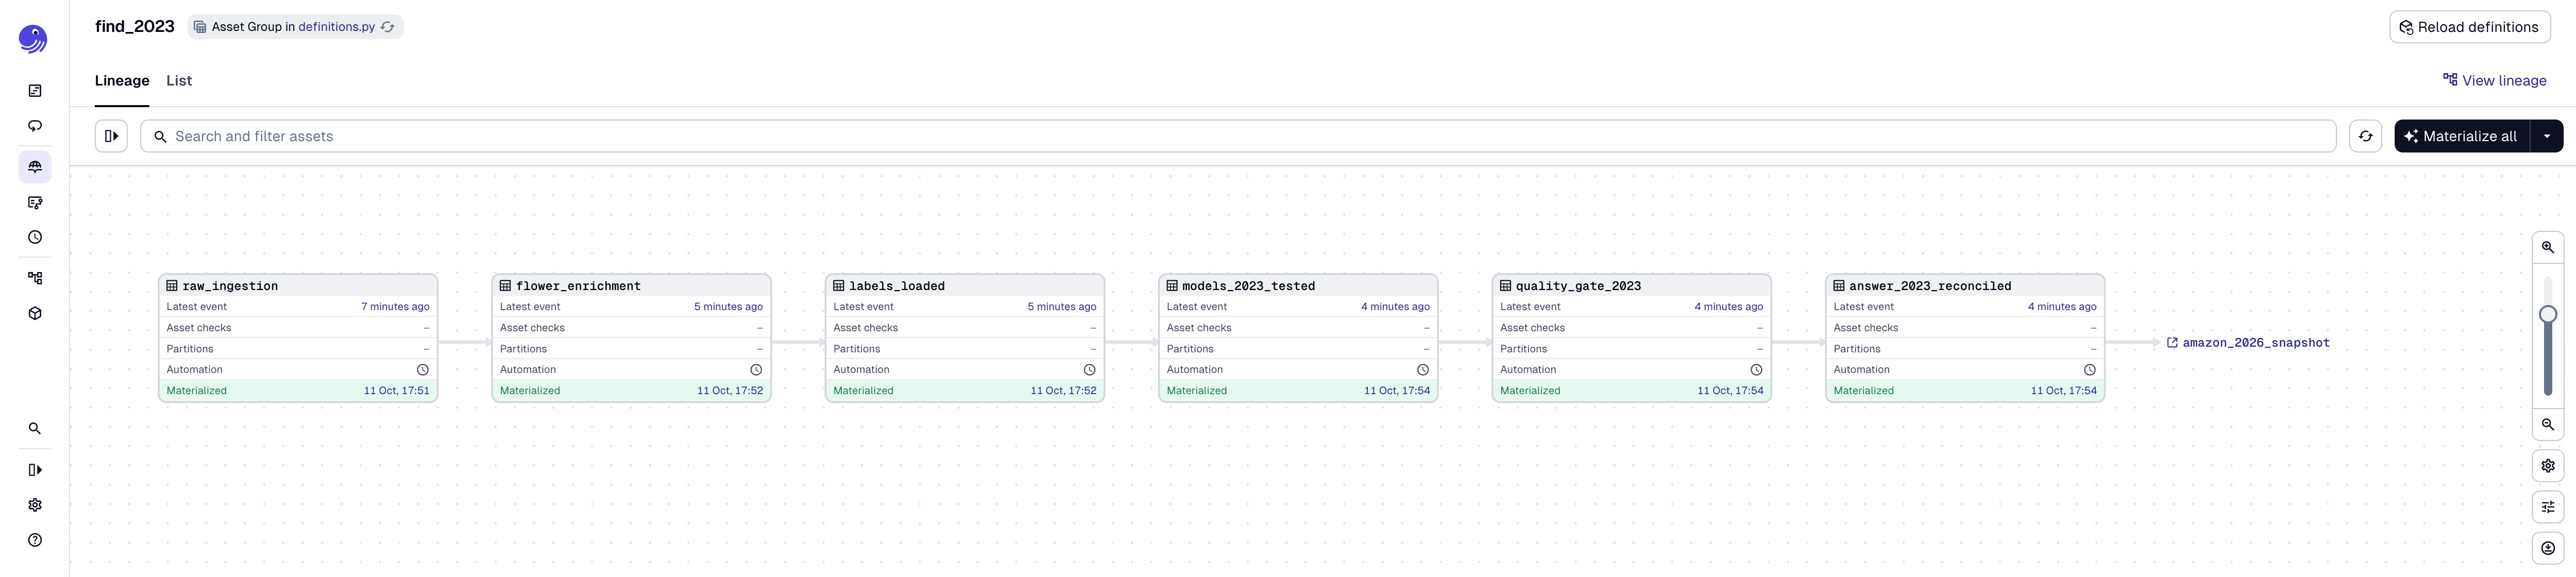

`dagster_job_schedule.png`

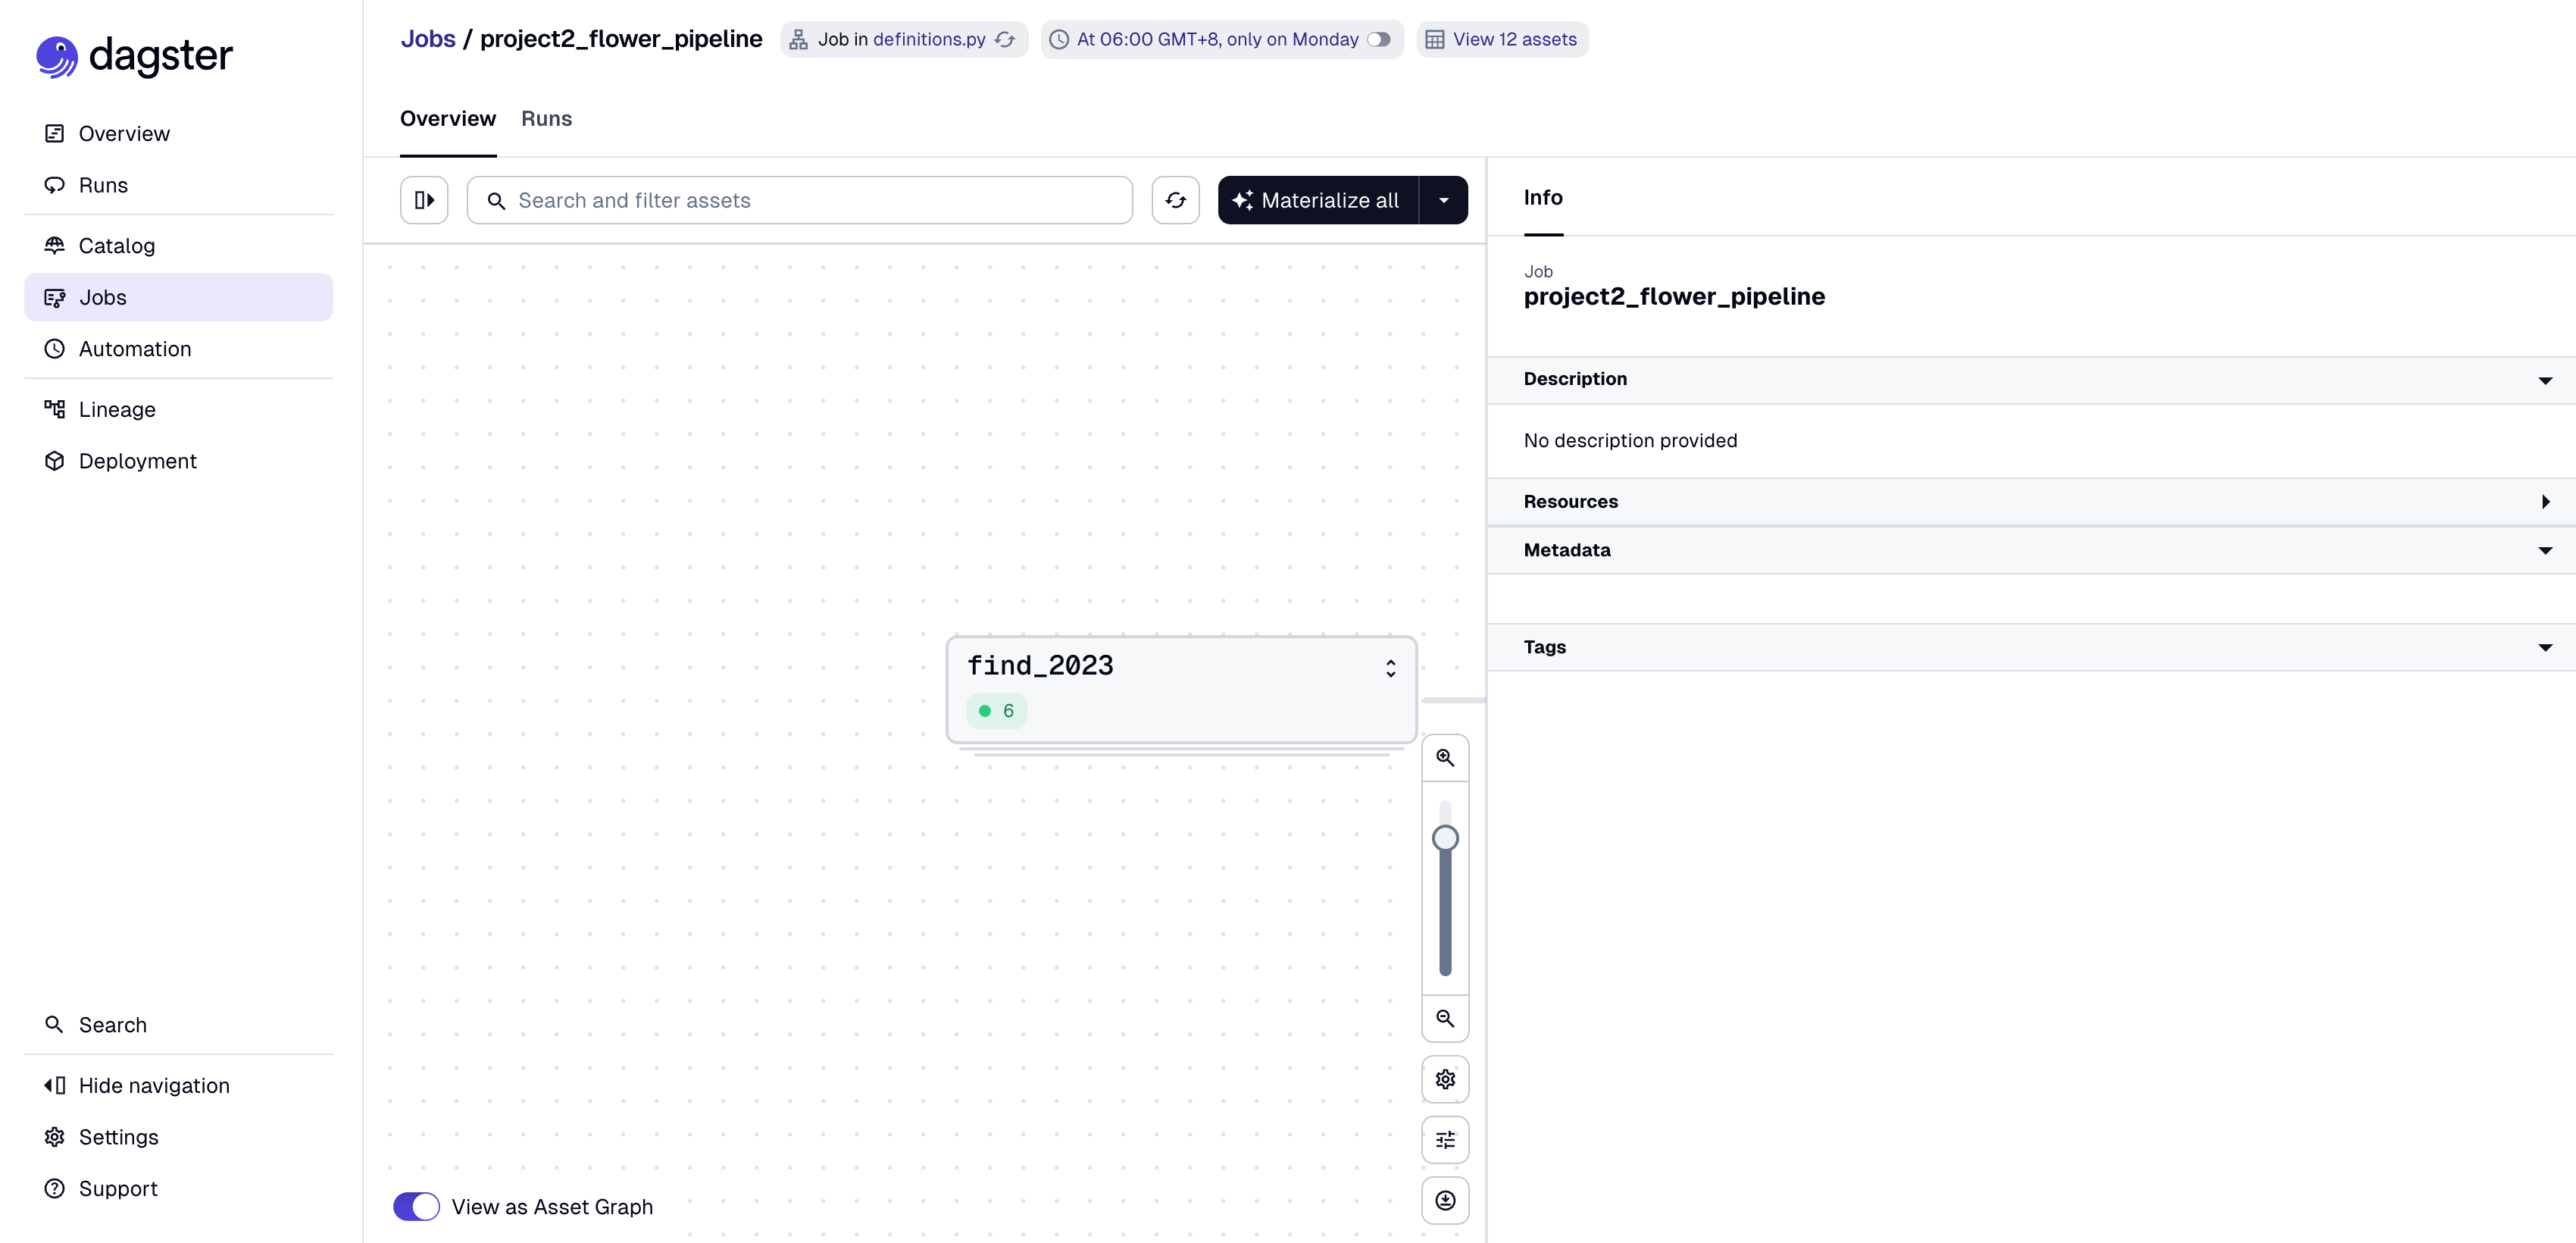

`dagster_run_success.png`

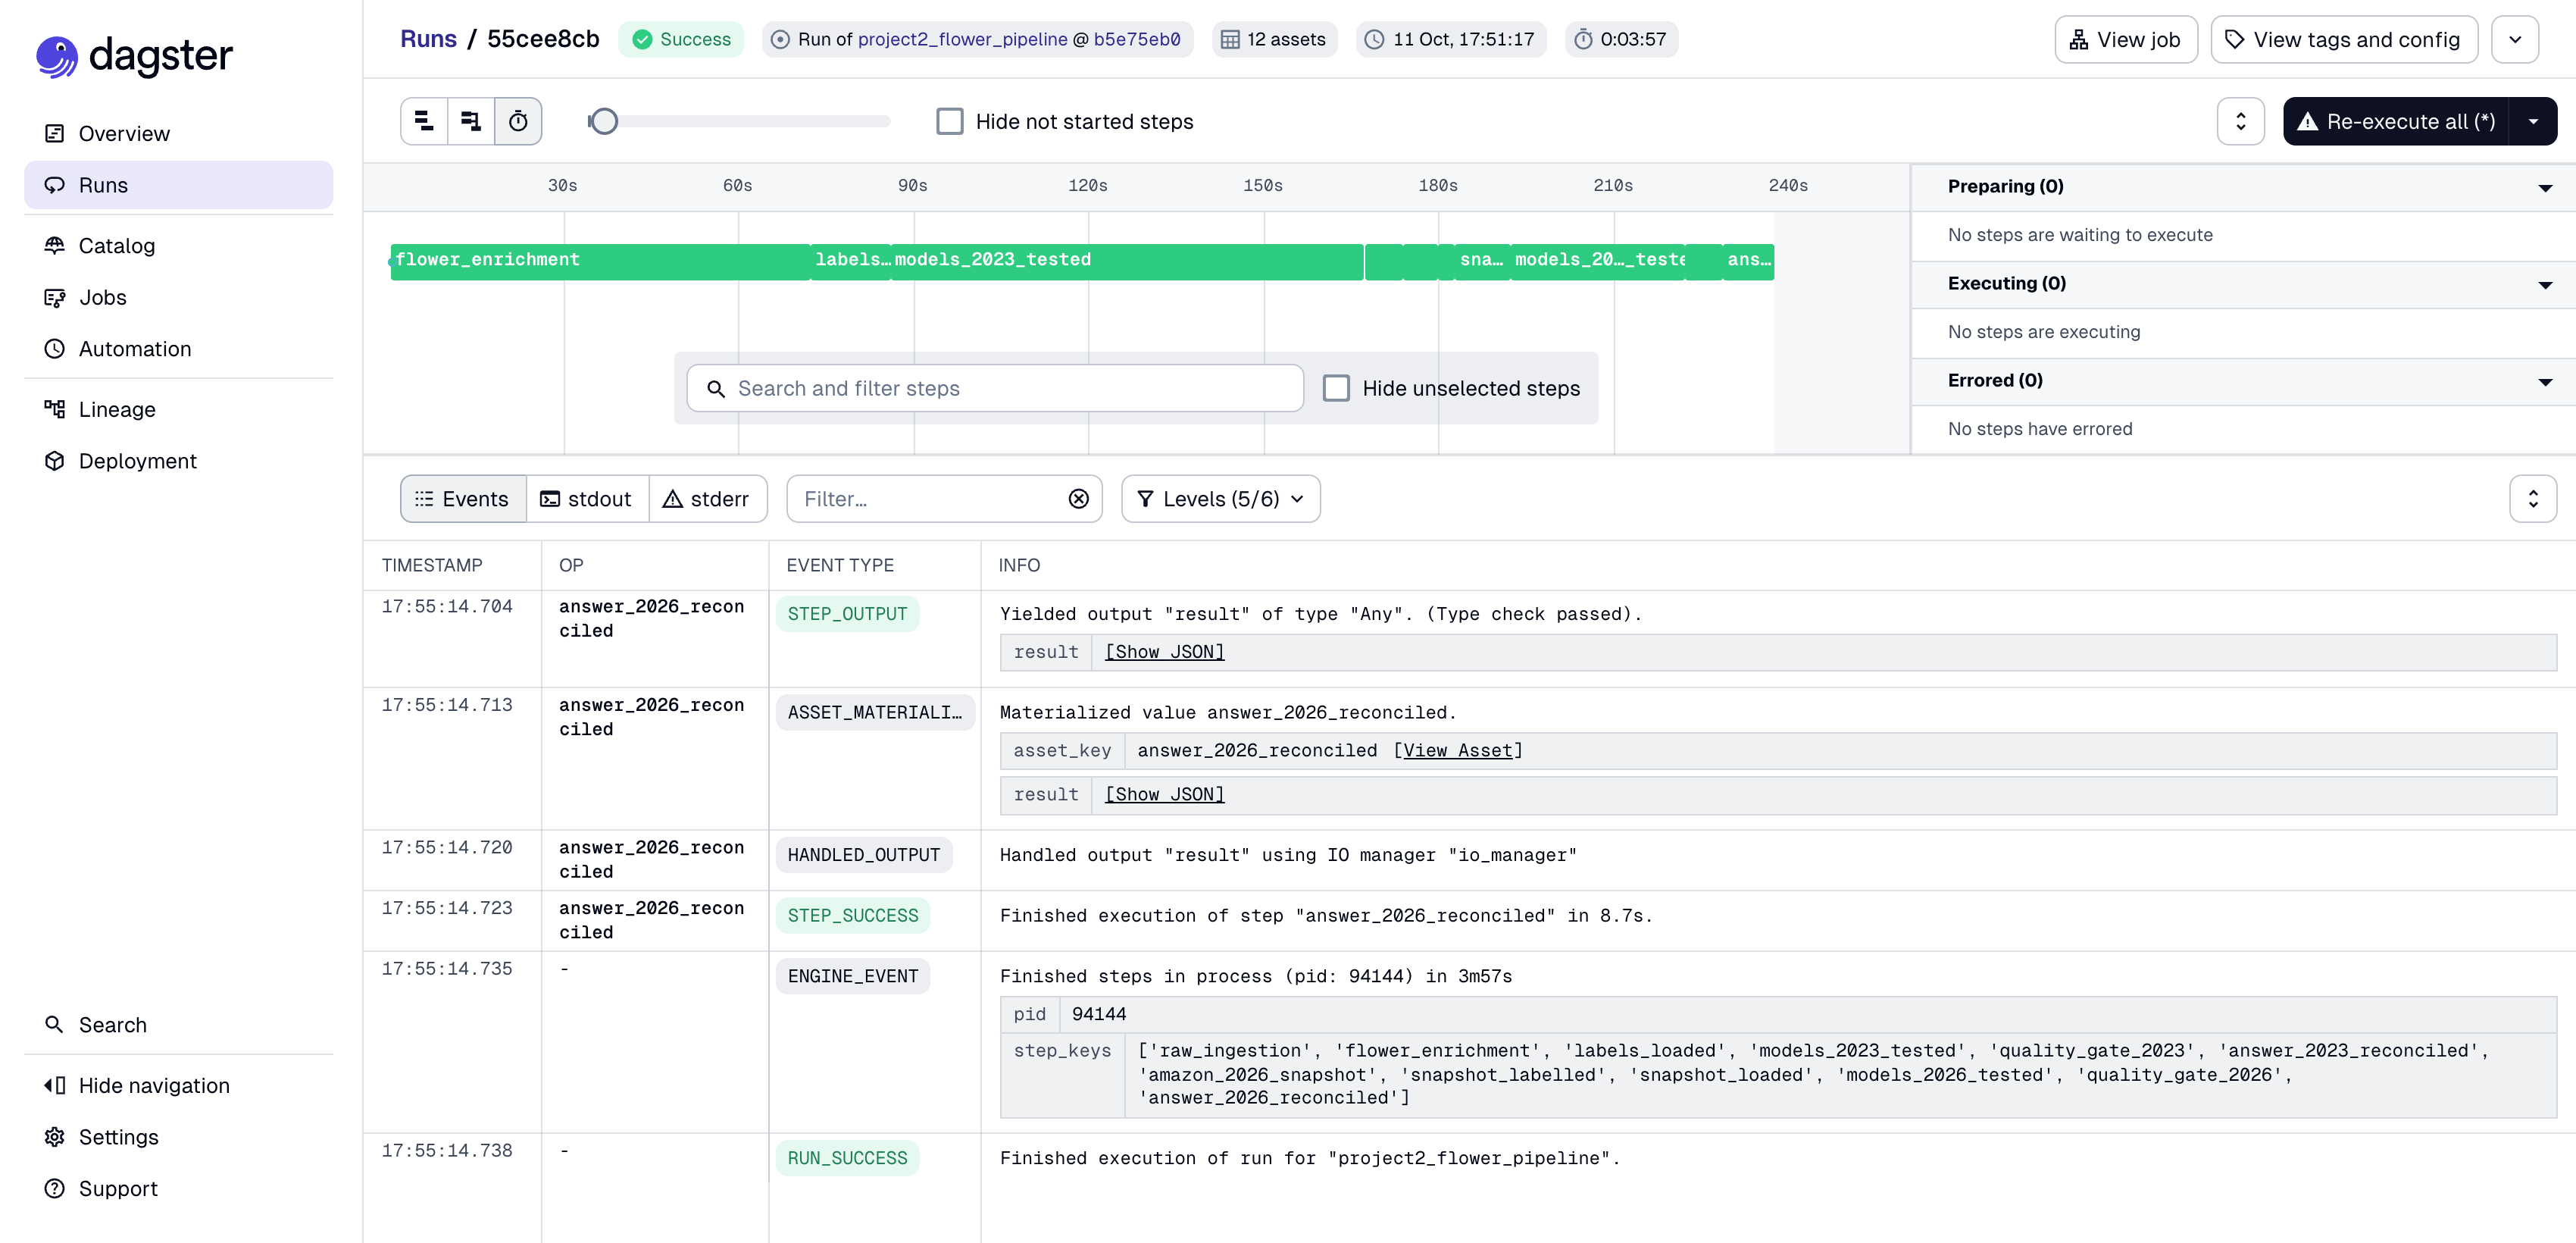

`dagster_verify_2026.png`

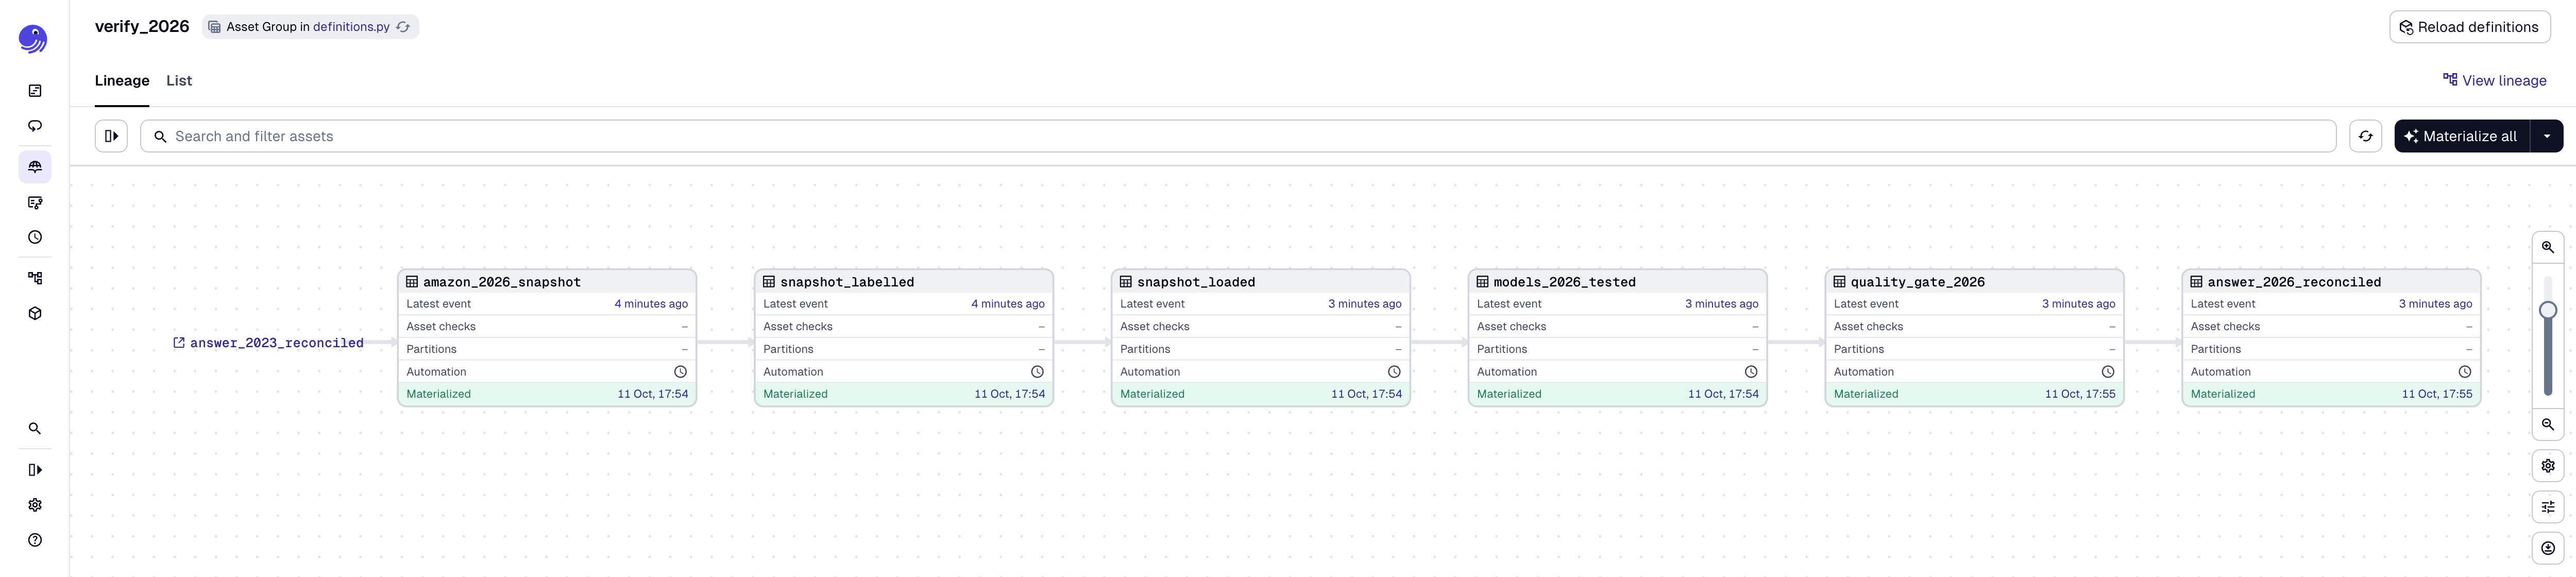

In [19]:
for png in sorted((REPO / 'docs' / 'screenshots').glob('dagster_*.png')):
    display(Markdown(f'`{png.name}`'), Image(filename=str(png), width=900))

## 8 · Analyse
The analysis (monthly trend, top products, customer segments, Amazon 2026) continues in
[`flower_analysis.ipynb`](flower_analysis.ipynb), on the marts opened in step 4.

In [20]:
duck.close()